### Package versions

Run the cell below to record the exact package versions used to generate the results in this notebook.


In [1]:
# --- Environment / package versions (added for reproducibility) ---
import sys
try:
    from importlib.metadata import version, PackageNotFoundError
except ImportError:  # Python < 3.8
    from importlib_metadata import version, PackageNotFoundError
print("Python:", sys.version.split()[0])
for _pkg in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn", "gseapy", "pyliftover", "openpyxl", "requests", "pyBigWig", "pyreadr", "adjustText", "pypdf"]:
    try:
        print(f"{_pkg}: {version(_pkg)}")
    except PackageNotFoundError:
        pass


Python: 3.10.12
numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
statsmodels: 0.14.6
matplotlib: 3.10.9
seaborn: 0.13.2
gseapy: 1.3.1
openpyxl: 3.1.5
requests: 2.34.2
pyreadr: 0.5.6
adjustText: 1.4.0
pypdf: 6.13.1


# SLC38A4 expression across hepatocyte cell types — figure and statistics

**Input:** `Fig2C_SLC38A4_cell_type_expression.csv`

Compares SLC38A4 mRNA (qPCR relative expression) across primary adult hepatocytes, primary foetal hepatocytes, Huh7.5 and HepG2. As these are **independent samples** and the readout is a **relative expression (fold-change)** ratio, group comparisons use an **unpaired Welch's t-test on log2-transformed values**, with primary adult hepatocytes as the reference; an overall Kruskal-Wallis test was computed.


## 1 · Imports and style

In [2]:
from itertools import combinations

import numpy as np
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt
from matplotlib.transforms import blended_transform_factory

np.random.seed(42)  # reproducible jitter

plt.rcParams.update({
    'font.family':          'sans-serif',
    'font.sans-serif':      ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size':            10,
    'axes.linewidth':       1.0,
    'axes.spines.top':      False,
    'axes.spines.right':    False,
    'xtick.major.width':    1.0,
    'ytick.major.width':    1.0,
    'xtick.major.size':     4,
    'ytick.major.size':     4,
    'savefig.dpi':          300,
    'pdf.fonttype':         42,   # editable text in Illustrator / Inkscape
    'ps.fonttype':          42,
})

## 2 · Load data

In [3]:
CSV_PATH = 'Fig2C_SLC38A4_cell_type_expression.csv'
df = pd.read_csv(CSV_PATH)

# Group order and display labels
GROUPS = [
    ('Primary foetal hepatocytes', 'Primary foetal\nhepatocytes'),
    ('Primary adult hepatocytes',  'Primary adult\nhepatocytes'),
    ('Huh7.5',                     'Huh7.5'),
    ('HepG2',                      'HepG2'),
]
keys   = [g[0] for g in GROUPS]
labels = [g[1] for g in GROUPS]

raw = {k: df.loc[df['cell_type'] == k, 'value'].tolist() for k in keys}

def _sem(x):
    return x.std(ddof=1) / np.sqrt(len(x))

summary = (
    df.groupby('cell_type', sort=False)['value']
    .agg(n='count', mean='mean', sem=_sem, minimum='min', maximum='max')
    .loc[keys]
    .reset_index()
    .rename(columns={'cell_type': 'key'})
)
summary.insert(1, 'label', [lbl.replace('\n', ' ') for lbl in labels])

print(summary[['label', 'n', 'mean', 'sem', 'minimum', 'maximum']]
      .to_string(index=False, float_format=lambda x: f'{x:.6f}'))

                     label  n     mean      sem  minimum  maximum
Primary foetal hepatocytes  3 3.381000 0.890013 2.179000 5.119000
 Primary adult hepatocytes  4 1.000000 0.106349 0.826000 1.302000
                    Huh7.5  3 1.193000 0.046228 1.119000 1.278000
                     HepG2  4 0.003750 0.000479 0.003000 0.005000


## 3 · Statistical analysis

Independent, unpaired **Welch's t-test on log2 relative expression** (each cell type vs primary adult hepatocytes), appropriate for qPCR fold-change data. Overall difference across cell types by Kruskal-Wallis.

In [4]:
REF = 'Primary adult hepatocytes'
arrs = {k: np.array(raw[k], dtype=float) for k in keys}

h, p_kw = stats.kruskal(*[arrs[k] for k in keys])
print(f'Overall Kruskal-Wallis: H = {h:.3f}, p = {p_kw:.4e}\n')

ref = np.log2(arrs[REF])
rows = []
for k in keys:
    if k == REF:
        continue
    lg = np.log2(arrs[k])
    t, p = stats.ttest_ind(lg, ref, equal_var=False)   # unpaired Welch, log2 scale
    rows.append({'Comparison': f"{k} vs adult",
                 'n': len(arrs[k]), 'n (adult)': len(ref),
                 'mean': round(float(arrs[k].mean()), 4),
                 'fold vs adult': round(float(arrs[k].mean() / arrs[REF].mean()), 2),
                 't': round(float(t), 3),
                 'p (Welch, log2)': p})
stats_df = pd.DataFrame(rows)
stats_df['Sig.'] = stats_df['p (Welch, log2)'].apply(
    lambda p: '****' if p < 1e-4 else '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else 'ns')
disp = stats_df.copy(); disp['p (Welch, log2)'] = disp['p (Welch, log2)'].map(lambda x: f'{x:.4f}')
display(disp)

Overall Kruskal-Wallis: H = 11.325, p = 1.0093e-02



,Comparison,n,n (adult),mean,fold vs adult,t,"p (Welch, log2)",Sig.
0,Primary foetal hepatocytes vs adult,3,4,3.3810,3.38,4.301,0.0298,*
1,Huh7.5 vs adult,3,4,1.1930,1.19,1.771,0.1546,ns
2,HepG2 vs adult,4,4,0.0037,0.00,-35.051,0.0000,****


## 4 · Figure 2C

Bar chart (mean ± SEM) with individual data points overlaid.  
HepG2 values (~1×10⁻⁴) are essentially invisible on the linear scale — this is intentional, as it illustrates that HepG2 barely expresses SLC38A4 compared to the other cell types.

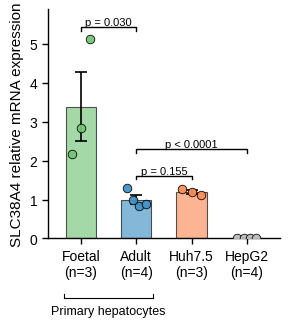

Saved: Fig2C_SLC38A4_cell_type_expression.pdf


In [5]:
COLORS = {
    'Primary foetal hepatocytes': '#74C476',  # green
    'Primary adult hepatocytes':  '#4393C3',  # blue
    'Huh7.5':                     '#FC8D59',  # orange
    'HepG2':                      '#BDBDBD',  # grey
}
SHORT = {'Primary foetal hepatocytes': 'Foetal', 'Primary adult hepatocytes': 'Adult',
         'Huh7.5': 'Huh7.5', 'HepG2': 'HepG2'}
REF = 'Primary adult hepatocytes'

# significance symbol (vs adult) per non-reference group, from the stats table
pcol = 'p (Welch, log2)'
pval_map = {row['Comparison'].split(' vs ')[0]: row[pcol] for _, row in stats_df.iterrows()}
def fmt_p(p):
    return 'p < 0.0001' if p < 1e-4 else f'p = {p:.4f}' if p < 0.001 else f'p = {p:.3f}'

x = np.arange(len(keys))
span_max = max(np.mean(raw[k]) + (np.std(raw[k], ddof=1) / np.sqrt(len(raw[k])) if len(raw[k]) > 1 else 0)
               for k in keys)

fig, ax = plt.subplots(figsize=(3, 3))

for xi, (key, lbl) in enumerate(zip(keys, labels)):
    vals = np.array(raw[key])
    mn   = vals.mean()
    se   = vals.std(ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0.0
    c    = COLORS[key]
    ax.bar(xi, mn, width=0.55, color=c, alpha=0.65, edgecolor='black', linewidth=0.8, zorder=2)
    ax.errorbar(xi, mn, yerr=se, color='black', linewidth=1.2, capsize=4, capthick=1.2, zorder=3)
    off = np.linspace(-0.17, 0.17, len(vals)) if len(vals) > 1 else np.array([0.0])
    ax.scatter(xi + off, vals, color=c, edgecolors='black', linewidth=0.6, s=38, zorder=4, alpha=0.95)
    # significance annotation vs adult (reference gets none)

# significance brackets, placed just above each compared pair (all vs adult, index 1)
ax_idx = {k: i for i, k in enumerate(keys)}
def _top(k):
    v = np.array(raw[k]); se = v.std(ddof=1)/np.sqrt(len(v)) if len(v) > 1 else 0
    return max(v.mean() + se, v.max())
tops = {k: _top(k) for k in keys}
def _bracket(x0, x1, y, text):
    tick = span_max * 0.022
    ax.plot([x0, x0, x1, x1], [y, y + tick, y + tick, y], lw=1.0, c='black', clip_on=False)
    ax.text((x0 + x1) / 2, y + tick, text, ha='center', va='bottom', fontsize=8)
pad = span_max * 0.05
y_foe   = tops['Primary foetal hepatocytes'] + pad                       # near the tall foetal bar
short   = max(tops['Primary adult hepatocytes'], tops['Huh7.5'], tops['HepG2']) + pad
y_huh   = short                                                          # near the short bars
y_hepg2 = short + span_max * 0.16                                        # stacked above Huh7.5 bracket
_bracket(0, 1, y_foe,   fmt_p(pval_map['Primary foetal hepatocytes']))
_bracket(1, 2, y_huh,   fmt_p(pval_map['Huh7.5']))
_bracket(1, 3, y_hepg2, fmt_p(pval_map['HepG2']))

x_tick_labels = [f"{SHORT[k]}\n(n={len(raw[k])})" for k in keys]
ax.set_xticks(x)
ax.set_xticklabels(x_tick_labels, fontsize=10)
ax.set_ylabel('SLC38A4 relative mRNA expression', fontsize=11)
ax.set_xlim(-0.6, len(keys) - 0.4)
ax.set_ylim(0, max(y_foe, y_hepg2) + span_max * 0.13)


plt.tight_layout()

trans  = blended_transform_factory(ax.transData, ax.transAxes)
y_line = -0.26
y_tick =  0.02
x0, x1 = -0.3, 1.3
ax.plot([x0, x1], [y_line, y_line], 'k-', lw=0.8, transform=trans, clip_on=False)
ax.plot([x0, x0], [y_line, y_line + y_tick], 'k-', lw=0.8, transform=trans, clip_on=False)
ax.plot([x1, x1], [y_line, y_line + y_tick], 'k-', lw=0.8, transform=trans, clip_on=False)
ax.text(0.5, y_line - 0.03, 'Primary hepatocytes', transform=trans, ha='center', va='top', fontsize=9)

fig.savefig('Fig2C_SLC38A4_cell_type_expression.pdf', bbox_inches='tight')
plt.show()
print('Saved: Fig2C_SLC38A4_cell_type_expression.pdf')

## 5 · Supplementary data

Three sheets: individual data points, per-group summary statistics, and pairwise comparisons against primary adult hepatocytes as reference.  
Exported to `Fig2C_SLC38A4_cell_type_expression_supplementary_data.xlsx`.

In [6]:
# -- Sheet 1: individual values --
supp_vals = pd.DataFrame([
    {'Cell type': lbl.replace('\n', ' '),
     'Replicate': i + 1,
     'SLC38A4 relative mRNA expression': round(v, 8)}
    for k, lbl in GROUPS
    for i, v in enumerate(raw[k])
])

# -- Sheet 2: summary statistics --
supp_summ = (
    summary[['label', 'n', 'mean', 'sem', 'minimum', 'maximum']]
    .rename(columns={'label': 'Cell type', 'mean': 'Mean', 'sem': 'SEM',
                     'minimum': 'Minimum', 'maximum': 'Maximum'})
    .round(8)
)

# -- Sheet 3: statistics (unpaired Welch t-test on log2 relative expression, adult reference) --
supp_stats = stats_df.copy().reset_index(drop=True)

print('=== Individual data points ===')
display(supp_vals)
print('\n=== Summary statistics ===')
display(supp_summ)
print('\n=== Comparisons vs primary adult hepatocytes (unpaired Welch t-test on log2 relative expression) ===')
display(supp_stats)

# -- Export to Excel --
out_path = 'Fig2C_SLC38A4_cell_type_expression_supplementary_data.xlsx'
with pd.ExcelWriter(out_path, engine='openpyxl') as writer:
    supp_vals.to_excel(writer,  sheet_name='Individual values',  index=False)
    supp_summ.to_excel(writer,  sheet_name='Summary statistics', index=False)
    supp_stats.to_excel(writer, sheet_name='Statistics',         index=False)

print(f'\nSaved: {out_path}')

=== Individual data points ===


,Cell type,Replicate,SLC38A4 relative mRNA expression
0,Primary foetal hepatocytes,1,2.179
1,Primary foetal hepatocytes,2,2.845
2,Primary foetal hepatocytes,3,5.119
3,Primary adult hepatocytes,1,1.302
4,Primary adult hepatocytes,2,0.991
5,Primary adult hepatocytes,3,0.826
6,Primary adult hepatocytes,4,0.881
7,Huh7.5,1,1.278
8,Huh7.5,2,1.182
9,Huh7.5,3,1.119



=== Summary statistics ===


,Cell type,n,Mean,SEM,Minimum,Maximum
0,Primary foetal hepatocytes,3,3.38100,0.890013,2.179,5.119
1,Primary adult hepatocytes,4,1.00000,0.106349,0.826,1.302
2,Huh7.5,3,1.19300,0.046228,1.119,1.278
3,HepG2,4,0.00375,0.000479,0.003,0.005



=== Comparisons vs primary adult hepatocytes (unpaired Welch t-test on log2 relative expression) ===


,Comparison,n,n (adult),mean,fold vs adult,t,"p (Welch, log2)",Sig.
0,Primary foetal hepatocytes vs adult,3,4,3.3810,3.38,4.301,2.977974e-02,*
1,Huh7.5 vs adult,3,4,1.1930,1.19,1.771,1.545549e-01,ns
2,HepG2 vs adult,4,4,0.0037,0.00,-35.051,6.233082e-08,****



Saved: Fig2C_SLC38A4_cell_type_expression_supplementary_data.xlsx
